# Lab 2. Зниження розмірності, кластеризація та класифікація текстів

## ФБ-61мп Тютюннікова Віолета

## 1. Зниження розмірності та візуалізація даних

### Імпорт бібліотек

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, silhouette_score,
                             adjusted_rand_score, classification_report, confusion_matrix)

RANDOM_STATE = 42
PURPLE = "#8e7cc3"
LIGHT = "#c9bfe6"
soft = sns.light_palette(PURPLE, as_cmap=True)
DARK_TEXT = {"color": "#2d2440"}
CLASS_COLORS = {"Non-Tor": "#5e4fa2", "NonVPN": "#f28e2b", "Tor": "#d62728", "VPN": "#59a14f"}

### Підготовка даних

Повторюємо передобробку з Lab 1: видаляємо мітку іншої задачі Label.1, дублікати та константні ознаки, кодуємо Protocol через One-Hot і беремо вибірку 30 000 потоків зі збереженням пропорцій класів.

In [2]:
df = pd.read_parquet("cicdarknet2020.parquet")
target = "Label"

df = df.drop(columns=["Label.1"])
df = df.drop_duplicates()
const_cols = [c for c in df.columns if c != target and df[c].nunique() <= 1]
df = df.drop(columns=const_cols)

ohe = OneHotEncoder(sparse_output=False)
protocol_encoded = ohe.fit_transform(df[["Protocol"]])
protocol_df = pd.DataFrame(protocol_encoded,
                           columns=ohe.get_feature_names_out(["Protocol"]),
                           index=df.index)
df = pd.concat([df.drop(columns=["Protocol"]), protocol_df], axis=1)

df_s, _ = train_test_split(df, train_size=30000, stratify=df[target], random_state=RANDOM_STATE)
print("Розмір вибірки:", df_s.shape)
print(df_s[target].value_counts())

Розмір вибірки: (30000, 65)
Label
Non-Tor    19215
NonVPN      5387
VPN         5046
Tor          352
Name: count, dtype: int64


### Розділяємо на train/test та масштабуємо

Для kNN, PCA, t-SNE та K-Means ознаки мають бути в одному масштабі, тому застосовуємо StandardScaler, навчений лише на train.

In [3]:
X = df_s.drop(columns=target)
y = df_s[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

scaler = StandardScaler().fit(X_train)
scaled_X_train = scaler.transform(X_train)
scaled_X_test = scaler.transform(X_test)
print("Ознак до PCA:", scaled_X_train.shape[1])

Ознак до PCA: 64


### Класифікація до та після PCA

Беремо найкращу модель з Lab 1 - цу Random Forest. Спочатку навчаємо її на всіх масштабованих ознаках, потім застосовуємо PCA(n_components=0.95), тобто залишаємо стільки компонент, щоб зберегти 95% дисперсії, і навчаємо ту саму модель на стиснених даних. Порівнюємо accuracy, macro F1, кількість ознак і час навчання.

In [4]:
def fit_eval(X_tr, X_te, label):
    model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
    t0 = time.perf_counter()
    model.fit(X_tr, y_train)
    t1 = time.perf_counter()
    pred = model.predict(X_te)
    return {"Модель": label,
            "Ознак": X_tr.shape[1],
            "Accuracy": accuracy_score(y_test, pred),
            "Macro F1": f1_score(y_test, pred, average="macro"),
            "Час навчання, с": round(t1 - t0, 2)}

res_no_pca = fit_eval(scaled_X_train, scaled_X_test, "Без PCA")

pca = PCA(n_components=0.95, random_state=RANDOM_STATE).fit(scaled_X_train)
pca_X_train = pca.transform(scaled_X_train)
pca_X_test = pca.transform(scaled_X_test)
print(f"PCA залишив {pca.n_components_} компонент із {scaled_X_train.shape[1]}, "
      f"збережено {pca.explained_variance_ratio_.sum():.3f} дисперсії")

res_pca = fit_eval(pca_X_train, pca_X_test, "З PCA (0.95)")

compare = pd.DataFrame([res_no_pca, res_pca])
compare.round(4)

PCA залишив 26 компонент із 64, збережено 0.950 дисперсії


,Модель,Ознак,Accuracy,Macro F1,"Час навчання, с"
0,Без PCA,64,0.9730,0.9430,2.23
1,З PCA (0.95),26,0.9468,0.8929,5.90


### Графік накопиченої дисперсії

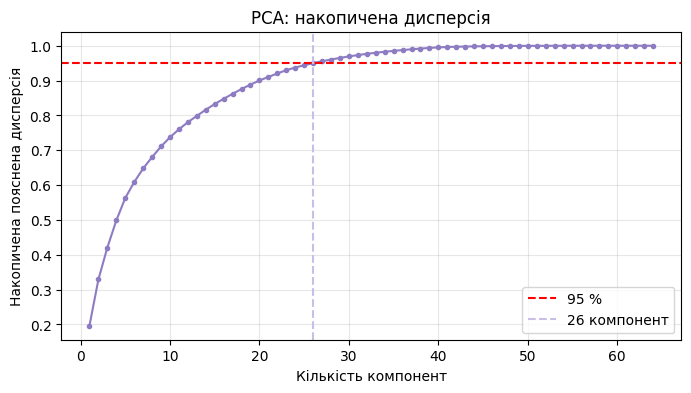

In [5]:
pca_full = PCA(random_state=RANDOM_STATE).fit(scaled_X_train)
cum = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum) + 1), cum, marker="o", color=PURPLE, markersize=3)
plt.axhline(0.95, color="red", linestyle="--", label="95 %")
plt.axvline(pca.n_components_, color=LIGHT, linestyle="--", label=f"{pca.n_components_} компонент")
plt.xlabel("Кількість компонент")
plt.ylabel("Накопичена пояснена дисперсія")
plt.title("PCA: накопичена дисперсія")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

PCA зберіг 95% дисперсії, залишивши 26 компонент замість 64. Якість класифікації Random Forest при цьому знизилась: accuracy з 0.973 до 0.947, а macro F1 з 0.943 до 0.893. Macro F1 впала сильніше, бо вона чутлива до малих класів Tor і VPN, а саме їх розрізняють дрібні деталі, які потрапили у відкинуті 5% дисперсії. Час навчання не зменшився, а зріс приблизно у 2,5–3 рази. Причина в тому, що дерево шукає пороги по кожній ознаці, а компоненти PCA це щільні неперервні числа з великою кількістю унікальних значень, тоді як багато початкових ознак мали мало різних значень і ділились швидко. Крім того, PCA змішує ознаки, і межі класів, які були паралельні осям, стають похилими, що деревам незручно. Отже, для цього датасету PCA корисний для стиснення й візуалізації, але не для покращення чи прискорення Random Forest.

### t-SNE: візуалізація у 2D

t-SNE на 30 000 точок рахувався б дуже довго, тому беремо випадкову підвибірку 4000 потоків. Ініціалізуємо t-SNE через PCA для стабільності.

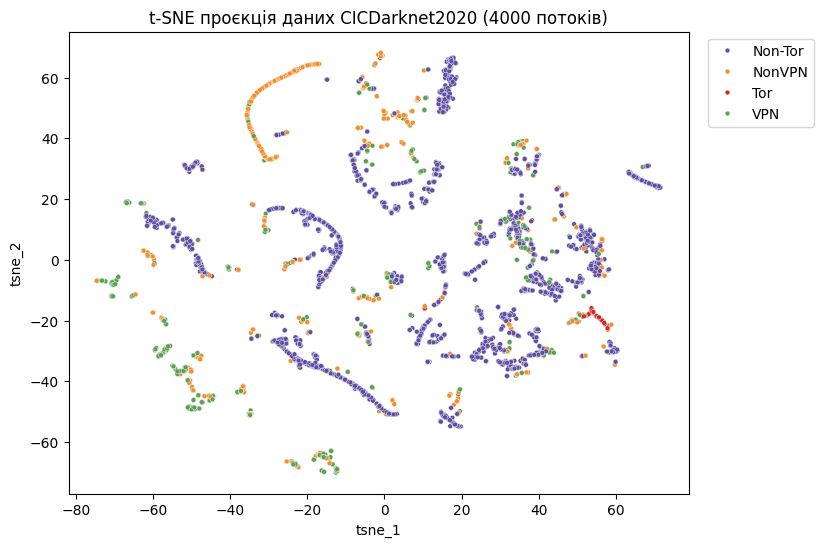

In [6]:
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(scaled_X_train), 4000, replace=False)
X_sub = scaled_X_train[idx]
y_sub = y_train.values[idx]

tsne = TSNE(n_components=2, init="pca", perplexity=30, random_state=RANDOM_STATE)
tsne_result = tsne.fit_transform(X_sub)

tsne_df = pd.DataFrame({"tsne_1": tsne_result[:, 0],
                        "tsne_2": tsne_result[:, 1],
                        "Клас": y_sub})

plt.figure(figsize=(8, 6))
sns.scatterplot(x="tsne_1", y="tsne_2", hue="Клас", data=tsne_df, s=12, palette=CLASS_COLORS)
plt.title("t-SNE проєкція даних")
plt.legend(bbox_to_anchor=(1.02, 1), loc=2)
plt.show()

t-SNE зберігає локальну структуру, тому дані розпались на багато дрібних згустків і витягнутих ланцюжків, кожен з яких це група схожих потоків (наприклад, сесії одного застосунку). Більшість згустків однорідні за класом. Tor (червоний) утворює один компактний окремий згусток праворуч унизу, бо його трафік має характерну структуру. NonVPN (помаранчевий) формує власні ланцюжки, зокрема велику дугу ліворуч угорі, а VPN (зелений) окремі групи ліворуч і внизу. Non-Tor найчисленніший і розкиданий по всій площині. Змішування класів помітне переважно в правій центральній частині, де поруч лежать Non-Tor, VPN і NonVPN. Така картина пояснює високу якість Random Forest з Lab 1: класи в основному розділені локально, хоча й не утворюють чотирьох великих хмар. Відстані між згустками в t-SNE не мають прямого змісту, важливо лише, хто з ким сусідить.

## 2. Кластерний аналіз (K-Means)

Кластеризуємо ту саму підвибірку 4000 масштабованих потоків методом K-Means і перевіряємо, чи збігається знайдена структура з реальними класами. Доцільну кількість кластерів визначаємо методом ліктя та за коефіцієнтом силуету.

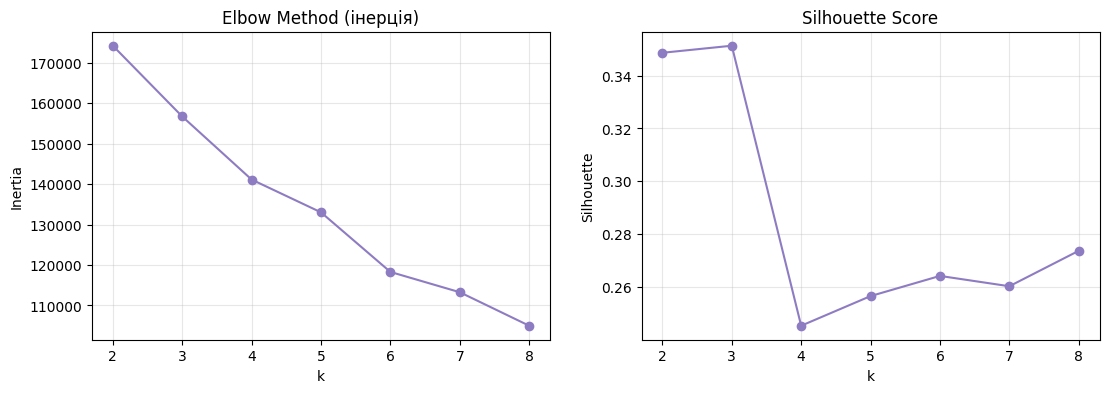

Найкраще k за силуетом: 3


In [7]:
K_range = range(2, 9)
inertias, silhouettes = [], []

X_clust = X_sub 
for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_clust)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_clust, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(list(K_range), inertias, marker="o", color=PURPLE)
ax[0].set_title("Elbow Method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia"); ax[0].grid(alpha=0.3)
ax[1].plot(list(K_range), silhouettes, marker="o", color=PURPLE)
ax[1].set_title("Silhouette Score"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette"); ax[1].grid(alpha=0.3)
plt.show()

best_k = list(K_range)[int(np.argmax(silhouettes))]
print("Найкраще k за силуетом:", best_k)

### Кластеризація з обраним k та візуалізація у 2D

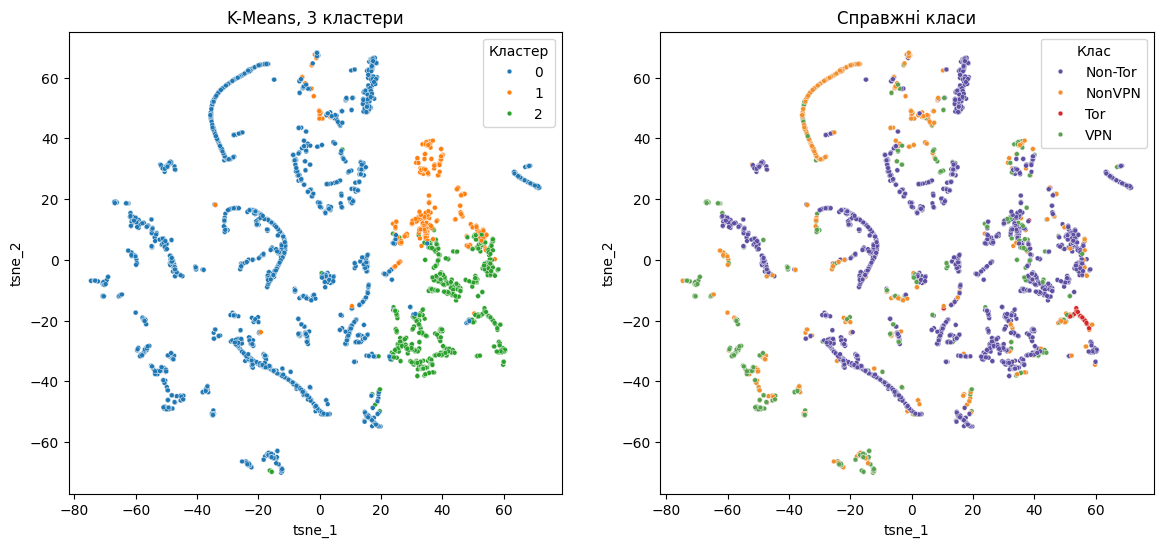

In [8]:
km = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10).fit(X_clust)
clusters = km.labels_

plot_df = pd.DataFrame({"tsne_1": tsne_result[:, 0],
                        "tsne_2": tsne_result[:, 1],
                        "Кластер": clusters,
                        "Клас": y_sub})

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(x="tsne_1", y="tsne_2", hue="Кластер", data=plot_df, s=12, palette="tab10", ax=ax[0])
ax[0].set_title(f"K-Means, {best_k} кластери")
sns.scatterplot(x="tsne_1", y="tsne_2", hue="Клас", data=plot_df, s=12, palette=CLASS_COLORS, ax=ax[1])
ax[1].set_title("Справжні класи")
plt.show()

### Порівняння кластерів зі справжніми класами

Таблиця відповідності клас — кластер:
Кластер     0    1    2
Клас                   
Non-Tor  1712  259  553
NonVPN    595   87   55
Tor         5    2   33
VPN       579   54   66

Adjusted Rand Index: -0.04


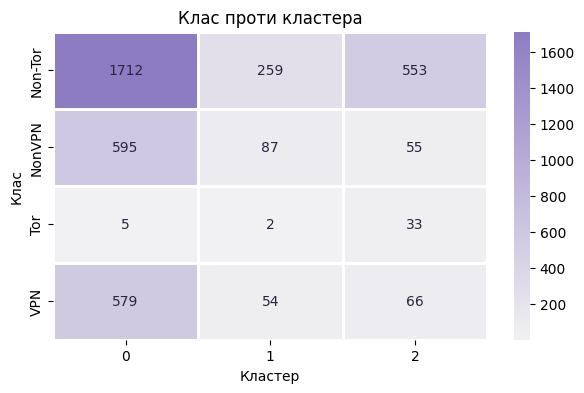

In [9]:
ct = pd.crosstab(plot_df["Клас"], plot_df["Кластер"])
print("Таблиця відповідності клас - кластер:")
print(ct)
print("\nAdjusted Rand Index:", round(adjusted_rand_score(y_sub, clusters), 3))

plt.figure(figsize=(7, 4))
sns.heatmap(ct, annot=True, fmt="d", cmap=soft, linewidths=1, linecolor="white", annot_kws=DARK_TEXT)
plt.title("Клас проти кластера")
plt.show()

### Чим відрізняються кластери

Щоб пояснити, за якою логікою K-Means поділив дані, дивимось на медіани кількох ключових ознак у кожному кластері (у початкових, немасштабованих одиницях).

In [10]:
key_cols = ["Flow Duration", "Total Fwd Packet", "Total Bwd packets",
            "Flow Bytes/s", "Packet Length Mean", "Idle Mean"]
X_sub_raw = X_train.iloc[idx]
summary = X_sub_raw[key_cols].groupby(clusters).median().round(1)
summary["Кількість потоків"] = pd.Series(clusters).value_counts().sort_index().values
summary

,Flow Duration,Total Fwd Packet,Total Bwd packets,Flow Bytes/s,Packet Length Mean,Idle Mean,Кількість потоків
0,292730.0,2.0,1.0,105.5,22.000000,0.000000e+00,2891
1,90157221.0,4.0,3.0,3.9,42.000000,1.436960e+15,402
2,61224617.0,18.0,19.0,617.2,287.299988,1.437770e+15,707


Метод ліктя не дав чіткого згину - інерція спадає плавно, тому орієнтувались на силует, який максимальний при k = 3 (близько 0.35, при k = 2 майже стільки ж), а далі різко падає. Adjusted Rand Index дорівнює -0.04, тобто кластери практично не збігаються з класами, як і попереджає умова, кластер і клас це не одне й те саме. Таблиця відповідності показує, що кожен клас розподілений по всіх кластерах, а кластер 0 містить більшість потоків усіх класів. Медіани ознак пояснюють, за якою логікою K-Means поділив дані. Кластер 0 це короткі потоки (близько 0.3 с) з 1–2 пакетами, кластер 1 це довгі малоактивні з'єднання з кількома пакетами та дуже малою швидкістю, кластер 2 це довгі активні сесії з десятками пакетів і великим середнім розміром пакета. Тобто K-Means згрупував трафік за поведінкою, а не за тим, Tor це, VPN чи звичайне з'єднання. Єдиний помітний збіг це клас Tor, який майже весь (33 з 40) потрапив у кластер 2, адже Tor передає дані великими пакетами фіксованого розміру. Отже, знайдена кластерна структура реальна, але відображає тип активності, а не класи датасету.

## 3. Обробка та класифікація текстових даних

Для класифікації текстів беремо набір SMS Spam Collection, де є 5574 SMS-повідомлення англійською з мітками ham (звичайне) та spam. 

In [11]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from wordcloud import WordCloud

url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
sms = pd.read_csv(url, sep="\t", header=None, names=["label", "message"])
print("Розмір:", sms.shape)
print(sms["label"].value_counts())
sms.head()

Розмір: (5572, 2)
label
ham     4825
spam     747
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Класи незбалансовані, бо спаму близько 13%. Тому, як і в Lab 1, ділимо вибірку зі stratify і оцінюємо якість за macro F1, а не лише за accuracy.

### Передобробка текстів

Переводимо текст у нижній регістр, прибираємо пунктуацію й цифри, видаляємо англійські стоп-слова та слова коротші за 3 літери.

In [12]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [w for w in text.split() if w not in ENGLISH_STOP_WORDS and len(w) > 2]
    return " ".join(tokens)

sms["clean"] = sms["message"].apply(clean_text)
sms[["message", "clean"]].head()

,message,clean
0,"Go until jurong point, crazy.. Available only ...",jurong point crazy available bugis great world...
1,Ok lar... Joking wif u oni...,lar joking wif oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win cup final tkts text r...
3,U dun say so early hor... U c already then say...,dun say early hor say
4,"Nah I don't think he goes to usf, he lives aro...",nah don think goes usf lives


### WordCloud для кожного класу

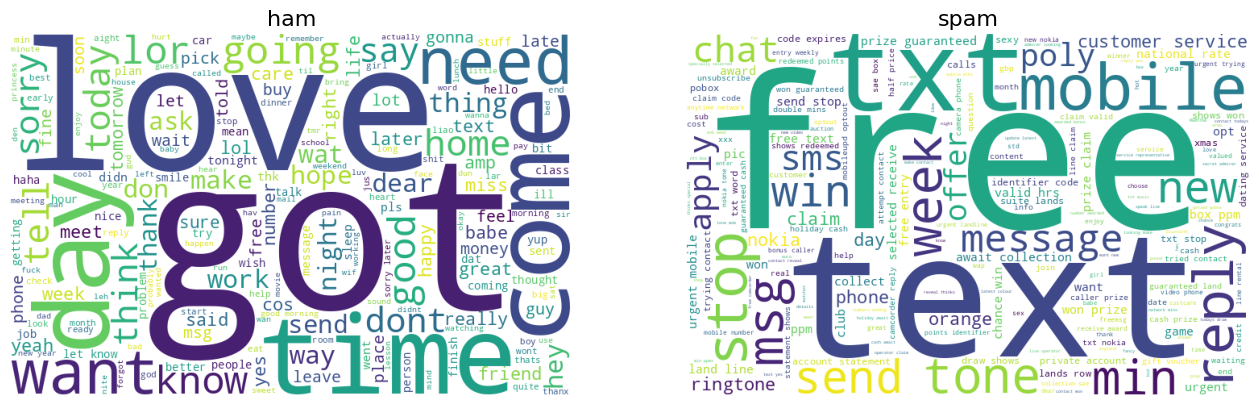

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, cls in zip(axes, ["ham", "spam"]):
    text = " ".join(sms.loc[sms["label"] == cls, "clean"])
    wc = WordCloud(width=700, height=450, background_color="white",
                   colormap="viridis", random_state=RANDOM_STATE).generate(text)
    ax.imshow(wc)
    ax.axis("off")
    ax.set_title(cls, fontsize=16)
plt.show()

Хмари слів чітко відрізняються. У ham переважають розмовні слова got, love, time, day, come, know, want, need, тобто звичайне листування між людьми. У spam домінують free, txt, text, mobile, claim, reply, stop, win, prize, tone, тобто заклики щось отримати, відповісти чи надіслати повідомлення, типові для шахрайських і рекламних розсилок. Через таку різну лексику класи добре розділяються навіть простою моделлю на частотах слів.

### Векторизація TF-IDF та класифікація

Ділимо дані на train/test, векторизуємо тексти через TfidfVectorizer, який зважує слово за частотою в повідомленні та рідкістю в усій колекції. Беремо окремі слова та біграми (ngram_range=(1, 2)). Навчаємо логістичну регресію з class_weight="balanced", щоб модель не ігнорувала менший клас spam.

In [14]:
Xtr_txt, Xte_txt, ytr_txt, yte_txt = train_test_split(
    sms["clean"], sms["label"], test_size=0.20, stratify=sms["label"], random_state=RANDOM_STATE)

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
Xtr = tfidf.fit_transform(Xtr_txt)
Xte = tfidf.transform(Xte_txt)
print("Розмір словника:", len(tfidf.vocabulary_))

clf = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
clf.fit(Xtr, ytr_txt)
pred = clf.predict(Xte)

print("Accuracy:", round(accuracy_score(yte_txt, pred), 4))
print("Macro F1:", round(f1_score(yte_txt, pred, average="macro"), 4))
print(classification_report(yte_txt, pred, digits=3))

Розмір словника: 6195
Accuracy: 0.974
Macro F1: 0.9443
              precision    recall  f1-score   support

         ham      0.987     0.983     0.985       966
        spam      0.895     0.913     0.904       149

    accuracy                          0.974      1115
   macro avg      0.941     0.948     0.944      1115
weighted avg      0.974     0.974     0.974      1115



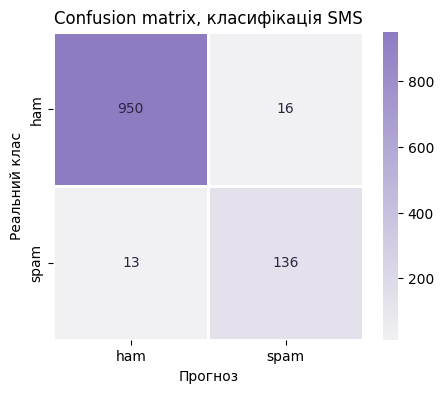

In [15]:
cm = confusion_matrix(yte_txt, pred, labels=["ham", "spam"])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap=soft, linewidths=1, linecolor="white",
            xticklabels=["ham", "spam"], yticklabels=["ham", "spam"], annot_kws=DARK_TEXT)
plt.xlabel("Прогноз"); plt.ylabel("Реальний клас")
plt.title("Confusion matrix")
plt.show()

### Найважливіші слова для моделі

In [16]:
coef = pd.Series(clf.coef_[0], index=tfidf.get_feature_names_out())
print("Найсильніші ознаки spam:", coef.sort_values(ascending=False).head(10).index.tolist())
print("Найсильніші ознаки ham:", coef.sort_values().head(10).index.tolist())

Найсильніші ознаки spam: ['txt', 'www', 'claim', 'mobile', 'free', 'reply', 'stop', 'service', 'text', 'new']
Найсильніші ознаки ham: ['home', 'got', 'sorry', 'come', 'lor', 'hey', 'later', 'good', 'way', 'yeah']


Логістична регресія на TF-IDF досягла accuracy 0.974 і macro F1 0.944. Для ham precision 0.987 і recall 0.983, для spam precision 0.895 і recall 0.913. За матрицею помилок модель пропустила 13 спам-повідомлень із 149 і помилково позначила як спам 16 звичайних із 966. Завдяки зважуванню класів модель не ігнорує менший клас, тому recall спаму вищий за 0.9. Найсильніші ознаки спаму txt, www, claim, mobile, free, reply, stop, а звичайних повідомлень home, sorry, come, later, good, що збігається з хмарами слів. Accuracy тут завищує враження через дисбаланс класів, тому головною метрикою є macro F1.

## Висновок

У роботі розглянуто три базові задачі навчання без учителя та обробки текстів. PCA стиснув 64 ознаки до 26 зі збереженням 95 % дисперсії, але для Random Forest це знизило macro F1 з 0.943 до 0.893 і у 2,5–3 рази збільшило час навчання. t-SNE показав, що дані складаються з багатьох однорідних за класом згустків, Tor утворює окрему групу, а змішування класів трапляється лише в частині простору. K-Means з k = 3 згрупував потоки за типом активності, а не за класами (ARI -0.04), що підтверджує різницю між кластером і класом. Для текстів зв'язка передобробка, WordCloud, TF-IDF і логістична регресія виявила спам-повідомлення з macro F1 0.944.